---
# <div align="center"><font color='blue'> COSC 2779/2972 | Deep Learning </font></div>
## <div align="center"><font color='blue'> Week 8 Lab: Transformers & Text Classification</font></div>
---

This week we complete the progression from bag-of-words → RNNs → transformers. We continue with the **same HappyDB task** from Week 7 so you can directly compare all approaches on equal footing.

Rather than processing text sequentially like RNNs, transformers use **attention mechanisms** to model relationships between all words simultaneously. This enables parallelisation, better handling of long-range dependencies, and — most importantly — pretrained models that transfer remarkably well to new tasks.

## 🎯 Learning Objectives

By the end of this lab, you should be able to:

- Explain why transformers replaced recurrent models as the dominant NLP architecture
- Understand the intuition behind self-attention
- Build a simple transformer encoder for classification using PyTorch
- Use transformer tokenisers (subword tokenisation) and understand why they matter
- Fine-tune a pretrained transformer (DistilBERT) using Hugging Face
- Compare transformers with RNN/LSTM models from Week 7
- Analyse transformer predictions, biases, and limitations

**Prerequisites:** Week 7 (RNNs, LSTMs, GRUs, embeddings, HappyDB)

**Duration:** ~2–3 hours


## Setup

In [1]:
!pip install -q transformers datasets

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.model_selection import train_test_split
import re, os, math

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


### Training Utilities

In [2]:
def train_one_epoch(model, loader, optimizer, criterion, tokenizer_mode=False):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for batch in loader:
        if tokenizer_mode:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            y = batch['labels'].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=y)
            loss = outputs.loss
            logits = outputs.logits
        else:
            x, y, lengths = batch
            x, y = x.to(device), y.to(device)
            logits = model(x, lengths)
            loss = criterion(logits, y)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * y.size(0)
        _, predicted = torch.max(logits, 1)
        correct += (predicted == y).sum().item()
        total += y.size(0)
    return total_loss / total, correct / total


def evaluate_model(model, loader, criterion, tokenizer_mode=False):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.inference_mode():
        for batch in loader:
            if tokenizer_mode:
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                y = batch['labels'].to(device)
                outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=y)
                loss = outputs.loss
                logits = outputs.logits
            else:
                x, y, lengths = batch
                x, y = x.to(device), y.to(device)
                logits = model(x, lengths)
                loss = criterion(logits, y)
            
            total_loss += loss.item() * y.size(0)
            _, predicted = torch.max(logits, 1)
            correct += (predicted == y).sum().item()
            total += y.size(0)
    return total_loss / total, correct / total


def run_experiment(model, optimizer, criterion, train_loader, val_loader,
                   epochs=10, name='Model', tokenizer_mode=False):
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    for epoch in range(epochs):
        tl, ta = train_one_epoch(model, train_loader, optimizer, criterion, tokenizer_mode)
        vl, va = evaluate_model(model, val_loader, criterion, tokenizer_mode)
        history['train_loss'].append(tl)
        history['train_acc'].append(ta)
        history['val_loss'].append(vl)
        history['val_acc'].append(va)
        if (epoch + 1) % max(1, epochs // 5) == 0 or epoch == 0:
            print(f'  [{name}] Epoch {epoch+1}/{epochs} — '
                  f'Train: {tl:.4f} / {ta:.4f} | Val: {vl:.4f} / {va:.4f}')
    return history


def plot_experiments(results, show_train=True, show_val=True):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for name, hist in results.items():
        epochs = range(1, len(hist['train_loss']) + 1)
        if show_train:
            axes[0].plot(epochs, hist['train_loss'], label=f'{name} (Train)', marker='o', markersize=3)
            axes[1].plot(epochs, hist['train_acc'], label=f'{name} (Train)', marker='o', markersize=3)
        if show_val:
            axes[0].plot(epochs, hist['val_loss'], label=f'{name} (Val)', linestyle='--', marker='x', markersize=3)
            axes[1].plot(epochs, hist['val_acc'], label=f'{name} (Val)', linestyle='--', marker='x', markersize=3)
    for ax, ylabel in zip(axes, ['Loss', 'Accuracy']):
        ax.set_xlabel('Epoch'); ax.set_ylabel(ylabel); ax.set_title(ylabel)
        ax.legend(fontsize=8); ax.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

---
## Dataset: HappyDB (continued from Week 7)

We continue with the same HappyDB happiness category classification task so we can directly compare transformers against the RNN/LSTM models from last week.

In [3]:
# Download and prepare HappyDB (same as Week 7)
!wget -q https://raw.githubusercontent.com/megagonlabs/HappyDB/master/happydb/data/cleaned_hm.csv

df = pd.read_csv('cleaned_hm.csv')
df = df.dropna(subset=['predicted_category', 'cleaned_hm'])

label_names = sorted(df['predicted_category'].unique())
label_to_idx = {label: i for i, label in enumerate(label_names)}
NUM_CLASSES = len(label_names)

# Subsample for faster iteration
SUBSET_SIZE = 15000
texts = df['cleaned_hm'].tolist()
labels = [label_to_idx[c] for c in df['predicted_category']]

if SUBSET_SIZE < len(texts):
    texts, _, labels, _ = train_test_split(
        texts, labels, train_size=SUBSET_SIZE, random_state=42, stratify=labels
    )

# Train/val/test split: 70/15/15
X_temp, X_test, y_temp, y_test = train_test_split(
    texts, labels, test_size=0.15, random_state=42, stratify=labels
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.176, random_state=42, stratify=y_temp
)

print(f'Classes: {label_names}')
print(f'Training:   {len(X_train)}')
print(f'Validation: {len(X_val)}')
print(f'Test:       {len(X_test)} (held out)')

Classes: ['achievement', 'affection', 'bonding', 'enjoy_the_moment', 'exercise', 'leisure', 'nature']
Training:   10506
Validation: 2244
Test:       2250 (held out)


In [4]:
# Class weights for imbalanced data
class_counts = Counter(y_train)
total = sum(class_counts.values())
class_weights = torch.tensor(
    [total / class_counts[i] for i in range(NUM_CLASSES)],
    dtype=torch.float32
).to(device)
class_weights = class_weights / class_weights.sum() * NUM_CLASSES

print('Class weights (inverse frequency):')
for i, name in enumerate(label_names):
    print(f'  {name}: {class_weights[i].item():.2f}')

Class weights (inverse frequency):
  achievement: 0.12
  affection: 0.12
  bonding: 0.37
  enjoy_the_moment: 0.36
  exercise: 3.34
  leisure: 0.53
  nature: 2.16


---
# Part 1: Why Transformers?

### The Limitations of Recurrent Models

In Week 7, we built RNNs and LSTMs. They work, but have fundamental limitations:

1. **Sequential computation:** Each token must wait for the previous one to be processed. This prevents parallelisation and makes training slow on GPUs.

2. **Long-range dependencies are hard:** Even with gating (LSTM/GRU), information from early tokens is gradually diluted as the sequence gets longer.

3. **Fixed-size bottleneck:** The entire sentence meaning is compressed into a single hidden state vector.

Consider this sentence:

> *"The concert that my friends and I went to last weekend after finishing our exams was amazing."*

The word *"amazing"* at the end modifies *"concert"* at the beginning — separated by 15 tokens. An RNN must carry this information through every intermediate step.

### The Transformer Solution

Transformers (Vaswani et al., 2017, *"Attention Is All You Need"*) solve all three problems:

1. **Parallel processing:** All tokens are processed simultaneously, not sequentially.
2. **Direct connections:** Self-attention allows every token to attend directly to every other token, regardless of distance.
3. **No bottleneck:** The model maintains a representation for each token throughout, not just a single summary vector.

### 🤔 Questions

1. In the example sentence above, why would an RNN struggle to connect *"amazing"* to *"concert"*?
2. Why is parallel processing important for training on GPUs?
3. If transformers process all tokens at once, how do they know the order of words? (We'll answer this in Part 2.)

*Double-click here to write your answers...*

---
# Part 2: Attention Intuition

## What Is Attention?

Attention allows a model to **focus on the most relevant parts of the input** when processing each token. Instead of compressing the entire sequence into a single vector, attention computes a weighted combination of all token representations.

### The Mechanics (Simplified)

For each token, self-attention computes three vectors:
- **Query (Q):** "What am I looking for?"
- **Key (K):** "What do I contain?"
- **Value (V):** "What information do I provide?"

The attention score between two tokens is:

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right) V$$

In plain terms: each token compares its Query against every other token's Key to compute relevance scores, then combines the Values weighted by those scores.

### Task 2.1 — Manual Attention Analysis

For each sentence below, identify which words should attend most strongly to each other, and explain why:

1. *"I really enjoyed the concert"*
2. *"I thought the trip would be fun but it was exhausting"*
3. *"I am not unhappy"*
4. *"My family surprised me with a birthday party"*

### 🤔 Questions 

1. In sentence 2, which word does *"exhausting"* need to attend to in order to understand the overall sentiment?
2. In sentence 3, why is the relationship between *"not"* and *"unhappy"* critical? Could a bag-of-words model handle this?
3. How is attention different from the simple RNN hidden state?

*Double-click here to write your answers...*

---
# Part 3: Build a Tiny Transformer

Before using a pretrained model, let's build a small transformer encoder from scratch to understand the components.

### The Architecture

```
Input tokens
  → Token Embedding
  → Positional Encoding (tells the model about word order)
  → Transformer Encoder (self-attention + feedforward)
  → Mean Pooling (aggregate token representations)
  → Classification Head
```

### Positional Encoding

Since transformers process all tokens in parallel, they have no notion of word order. **Positional encodings** are added to the token embeddings to inject position information. The original paper uses sinusoidal functions:

$$PE_{(pos, 2i)} = \sin\left(\frac{pos}{10000^{2i/d}}\right), \quad PE_{(pos, 2i+1)} = \cos\left(\frac{pos}{10000^{2i/d}}\right)$$

### Week 7 Preprocessing (reused)

In [5]:
# Reuse the simple tokenizer and vocabulary from Week 7
def tokenize(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z0-9\s]', '', text)
    return text.split()

# Build vocabulary
all_train_tokens = [tokenize(t) for t in X_train]
word_counts = Counter()
for tokens in all_train_tokens:
    word_counts.update(tokens)

PAD_IDX, UNK_IDX = 0, 1
word_to_idx = {'<PAD>': PAD_IDX, '<UNK>': UNK_IDX}
idx = 2
for word, count in word_counts.most_common(10000 - 2):
    if count >= 5:
        word_to_idx[word] = idx
        idx += 1

VOCAB_SIZE = len(word_to_idx)
MAX_LEN = 50
print(f'Vocabulary: {VOCAB_SIZE}, Max length: {MAX_LEN}')

Vocabulary: 2576, Max length: 50


In [6]:
# Dataset class (same as Week 7)
class TextDataset(Dataset):
    def __init__(self, texts, labels, word_to_idx, max_len=MAX_LEN):
        self.labels = labels
        self.sequences, self.lengths = [], []
        for text in texts:
            tokens = tokenize(text)
            indices = [word_to_idx.get(t, UNK_IDX) for t in tokens[:max_len]]
            self.lengths.append(len(indices))
            indices += [PAD_IDX] * (max_len - len(indices))
            self.sequences.append(indices)
    
    def __len__(self):
        return len(self.labels)
    
    def __getitem__(self, idx):
        return (
            torch.tensor(self.sequences[idx], dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.long),
            self.lengths[idx],
        )

train_ds = TextDataset(X_train, y_train, word_to_idx)
val_ds = TextDataset(X_val, y_val, word_to_idx)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=256, shuffle=False)

### Positional Encoding

In [7]:
class PositionalEncoding(nn.Module):
    """Sinusoidal positional encoding from 'Attention Is All You Need'."""
    def __init__(self, d_model, max_len=500):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)  # (1, max_len, d_model)
        self.register_buffer('pe', pe)
    
    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

### Tiny Transformer Classifier

In [8]:
class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, embed_dim, num_heads, num_layers, num_classes, max_len=MAX_LEN):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.pos_encoding = PositionalEncoding(embed_dim, max_len)
        
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=0.1,
            batch_first=True,
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        
        self.fc = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(embed_dim, num_classes),
        )
    
    def forward(self, x, lengths=None):
        # Create padding mask: True where padded
        pad_mask = (x == PAD_IDX)  # (batch, seq_len)
        
        x = self.embedding(x)
        x = self.pos_encoding(x)
        x = self.transformer(x, src_key_padding_mask=pad_mask)
        
        # Mean pooling (mask out padding)
        mask = (~pad_mask).unsqueeze(-1).float()  # (batch, seq_len, 1)
        x = (x * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        
        return self.fc(x)

👉 **Note:** The tiny transformer uses `src_key_padding_mask` to tell the attention mechanism to ignore padding tokens. This is the transformer equivalent of the length-aware indexing we needed for RNNs in Week 7.

Parameters: 265,287


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


  [Tiny TF] Epoch 1/10 — Train: 1.7157 / 0.3133 | Val: 1.2572 / 0.5446
  [Tiny TF] Epoch 2/10 — Train: 1.1705 / 0.5371 | Val: 1.0437 / 0.5713
  [Tiny TF] Epoch 4/10 — Train: 0.6784 / 0.7180 | Val: 0.7805 / 0.6979
  [Tiny TF] Epoch 6/10 — Train: 0.4770 / 0.7908 | Val: 0.7940 / 0.7406
  [Tiny TF] Epoch 8/10 — Train: 0.3522 / 0.8382 | Val: 0.7727 / 0.7785
  [Tiny TF] Epoch 10/10 — Train: 0.2702 / 0.8755 | Val: 0.8069 / 0.7932


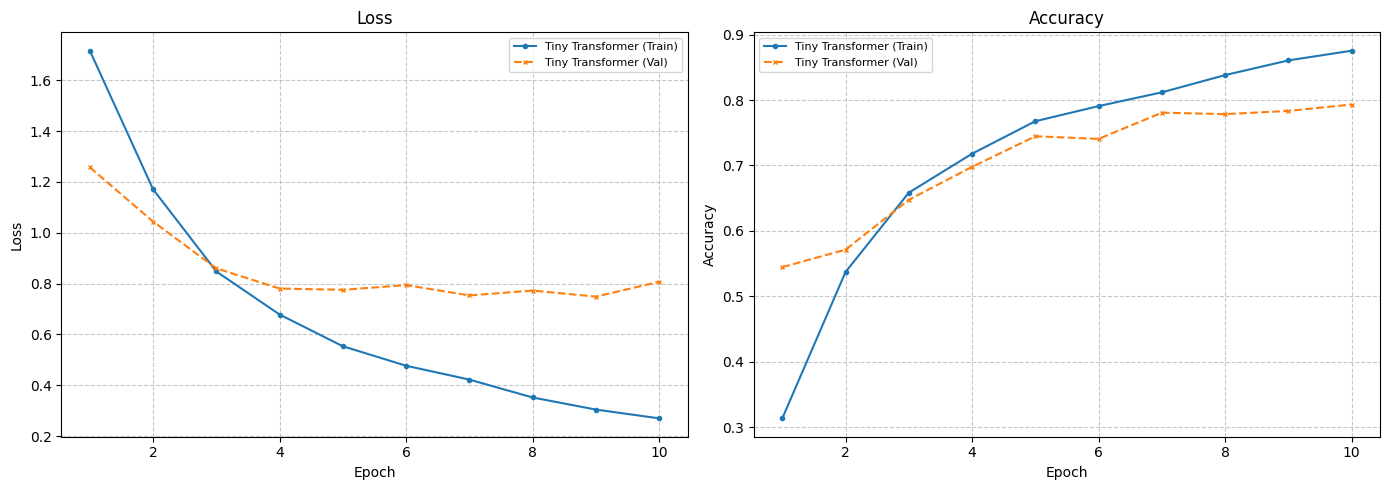

In [9]:
torch.manual_seed(0)
tiny_tf = TinyTransformer(
    vocab_size=VOCAB_SIZE,
    embed_dim=64,
    num_heads=4,
    num_layers=2,
    num_classes=NUM_CLASSES,
).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(tiny_tf.parameters(), lr=1e-3)

print(f'Parameters: {sum(p.numel() for p in tiny_tf.parameters()):,}')

all_results = {}
all_results['Tiny Transformer'] = run_experiment(
    tiny_tf, optimizer, criterion, train_loader, val_loader,
    epochs=10, name='Tiny TF'
)

plot_experiments(all_results)

### 🤔 Questions

1. How does the tiny transformer compare to the RNN/LSTM results from Week 7?
2. What advantages does parallel processing provide during training?
3. Why do we need positional encodings? What would happen without them?
4. The tiny transformer uses `src_key_padding_mask`. How is this similar to and different from the RNN padding fix in Week 7?

*Double-click here to write your answers...*

---
# Part 4: Transformer Tokenisation

## Why Transformer Tokenisers Are Different

In Week 7, we used a simple whitespace tokenizer that splits on spaces. Pretrained transformers use **subword tokenisers** that handle text very differently:

- **Subword splitting:** Unknown words are broken into known pieces ("unbelievable" → "un", "##believ", "##able")
- **No `<UNK>` problem:** Any word can be represented by combining subword pieces
- **Special tokens:** `[CLS]` (start), `[SEP]` (end), `[PAD]` are added automatically
- **Consistent with pretraining:** The tokeniser must match what the model saw during pretraining

In [10]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained('distilbert-base-uncased')

# Compare our simple tokenizer vs the transformer tokenizer
test_sentences = [
    "I am unbelievably happy today!",
    "My son's first steps were amazing.",
    "I can't believe I won $100!",
]

for sent in test_sentences:
    simple_tokens = str(sent).lower().split()
    tf_tokens = tokenizer.tokenize(sent)
    print(f'Original:    "{sent}"')
    print(f'Simple:      {simple_tokens}')
    print(f'Transformer: {tf_tokens}')
    print()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:103: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Original:    "I am unbelievably happy today!"
Simple:      ['i', 'am', 'unbelievably', 'happy', 'today!']
Transformer: ['i', 'am', 'un', '##bel', '##ie', '##va', '##bly', 'happy', 'today', '!']

Original:    "My son's first steps were amazing."
Simple:      ['my', "son's", 'first', 'steps', 'were', 'amazing.']
Transformer: ['my', 'son', "'", 's', 'first', 'steps', 'were', 'amazing', '.']

Original:    "I can't believe I won $100!"
Simple:      ['i', "can't", 'believe', 'i', 'won', '$100!']
Transformer: ['i', 'can', "'", 't', 'believe', 'i', 'won', '$', '100', '!']



In [11]:
# Inspect the full encoding (with special tokens and IDs)
encoded = tokenizer(
    "I am unbelievably happy",
    padding='max_length',
    truncation=True,
    max_length=12,
    return_tensors='pt'
)

print('Token IDs:      ', encoded['input_ids'][0].tolist())
print('Attention mask:  ', encoded['attention_mask'][0].tolist())
print('Decoded tokens:  ', tokenizer.convert_ids_to_tokens(encoded['input_ids'][0]))
print()
print('Notice:')
print('  - [CLS] at the start, [SEP] at the end')
print('  - "unbelievably" is split into subwords: un, ##believab, ##ly')
print('  - attention_mask is 1 for real tokens, 0 for padding')

Token IDs:       [101, 1045, 2572, 4895, 8671, 2666, 3567, 6321, 3407, 102, 0, 0]
Attention mask:   [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0]
Decoded tokens:   ['[CLS]', 'i', 'am', 'un', '##bel', '##ie', '##va', '##bly', 'happy', '[SEP]', '[PAD]', '[PAD]']

Notice:
  - [CLS] at the start, [SEP] at the end
  - "unbelievably" is split into subwords: un, ##believab, ##ly
  - attention_mask is 1 for real tokens, 0 for padding


### 🤔 Questions

1. Why are subword tokenisers better than word-level tokenisation? What problem do they solve?
2. What is the purpose of the `[CLS]` and `[SEP]` tokens?
3. What does the `attention_mask` do? How is this related to the padding problem we encountered in Week 7?
4. Why is it critical to use the **same tokeniser** that the pretrained model was trained with?

*Double-click here to write your answers...*

---
# Part 5: Fine-Tuning a Pretrained Transformer 

Now we use a pretrained transformer — **DistilBERT** — and fine-tune it for our classification task. This is the NLP equivalent of the transfer learning workflow we used for CNNs in Week 5.

DistilBERT is a smaller, faster version of BERT:
- 66M parameters (vs BERT's 110M)
- 60% faster, retains 97% of BERT's performance
- Pretrained on English Wikipedia + BookCorpus

### The Transfer Learning Parallel

| Week 5 (Vision) | Week 8 (NLP) |
|---|---|
| ResNet-18 pretrained on ImageNet | DistilBERT pretrained on Wikipedia |
| Replace final FC layer | Replace classification head |
| Linear probing → Fine-tuning | Freeze → Fine-tune |
| ImageNet normalisation | Transformer tokeniser |
| Learning rate ~1e-5 for fine-tuning | Learning rate ~2e-5 for fine-tuning |

### Prepare Dataset for Hugging Face

In [12]:
class HFDataset(Dataset):
    """Dataset compatible with Hugging Face transformer models."""
    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.labels = labels
        self.encodings = tokenizer(
            texts,
            padding='max_length',
            truncation=True,
            max_length=max_length,
            return_tensors='pt',
        )
    
    def __len__(self):
        return len(self.labels)
    
    def __getitem__(self, idx):
        return {
            'input_ids': self.encodings['input_ids'][idx],
            'attention_mask': self.encodings['attention_mask'][idx],
            'labels': torch.tensor(self.labels[idx], dtype=torch.long),
        }

hf_train_ds = HFDataset(X_train, y_train, tokenizer, max_length=64)
hf_val_ds = HFDataset(X_val, y_val, tokenizer, max_length=64)
hf_test_ds = HFDataset(X_test, y_test, tokenizer, max_length=64)

hf_train_loader = DataLoader(hf_train_ds, batch_size=32, shuffle=True)
hf_val_loader = DataLoader(hf_val_ds, batch_size=64, shuffle=False)
hf_test_loader = DataLoader(hf_test_ds, batch_size=64, shuffle=False)

print(f'HF Train: {len(hf_train_ds)}, Val: {len(hf_val_ds)}, Test: {len(hf_test_ds)}')

HF Train: 10506, Val: 2244, Test: 2250


### Load and Fine-Tune DistilBERT

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step 1: Linear Probing
  Trainable: 595,975 / 66,958,855 (0.89%)
  [DistilBERT probe] Epoch 1/5 — Train: 0.9092 / 0.6806 | Val: 0.7404 / 0.7259
  [DistilBERT probe] Epoch 2/5 — Train: 0.6946 / 0.7515 | Val: 0.6327 / 0.7767
  [DistilBERT probe] Epoch 3/5 — Train: 0.6398 / 0.7690 | Val: 0.6056 / 0.7825
  [DistilBERT probe] Epoch 4/5 — Train: 0.6268 / 0.7720 | Val: 0.6316 / 0.7643
  [DistilBERT probe] Epoch 5/5 — Train: 0.6009 / 0.7799 | Val: 0.5837 / 0.7963


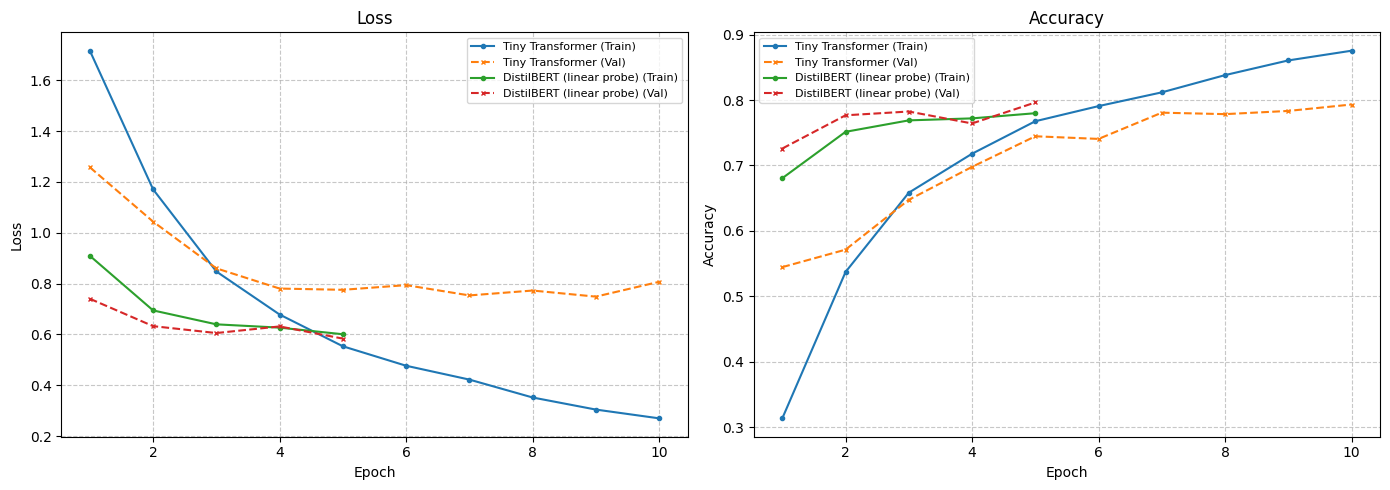

In [13]:
from transformers import AutoModelForSequenceClassification

# Load pretrained DistilBERT with a new classification head
distilbert = AutoModelForSequenceClassification.from_pretrained(
    'distilbert-base-uncased',
    num_labels=NUM_CLASSES,
    token=False,  # avoid authentication issues
).to(device)

# Step 1: Linear probing — freeze the transformer body, train only the classifier head
for param in distilbert.distilbert.parameters():
    param.requires_grad = False

trainable = sum(p.numel() for p in distilbert.parameters() if p.requires_grad)
total = sum(p.numel() for p in distilbert.parameters())
print(f'Step 1: Linear Probing')
print(f'  Trainable: {trainable:,} / {total:,} ({trainable/total*100:.2f}%)')

optimizer = optim.Adam(filter(lambda p: p.requires_grad, distilbert.parameters()), lr=1e-3)

all_results['DistilBERT (linear probe)'] = run_experiment(
    distilbert, optimizer, criterion, hf_train_loader, hf_val_loader,
    epochs=5, name='DistilBERT probe', tokenizer_mode=True
)

plot_experiments(all_results)

⚠️ **Important:** Transformer fine-tuning requires:
- **Much smaller learning rates** (2e-5 to 5e-5) — pretrained weights are already good; large updates would destroy them
- **Smaller batch sizes** — transformers use more memory per sample than RNNs
- **Fewer epochs** — pretrained models converge quickly; 3–5 epochs is often sufficient

Step 2: Fine-Tuning
  Trainable: 66,958,855 / 66,958,855 (100.00%)
  [DistilBERT fine-tune] Epoch 1/3 — Train: 0.4347 / 0.8410 | Val: 0.4033 / 0.8578
  [DistilBERT fine-tune] Epoch 2/3 — Train: 0.2777 / 0.8949 | Val: 0.4288 / 0.8538
  [DistilBERT fine-tune] Epoch 3/3 — Train: 0.1676 / 0.9397 | Val: 0.4879 / 0.8534


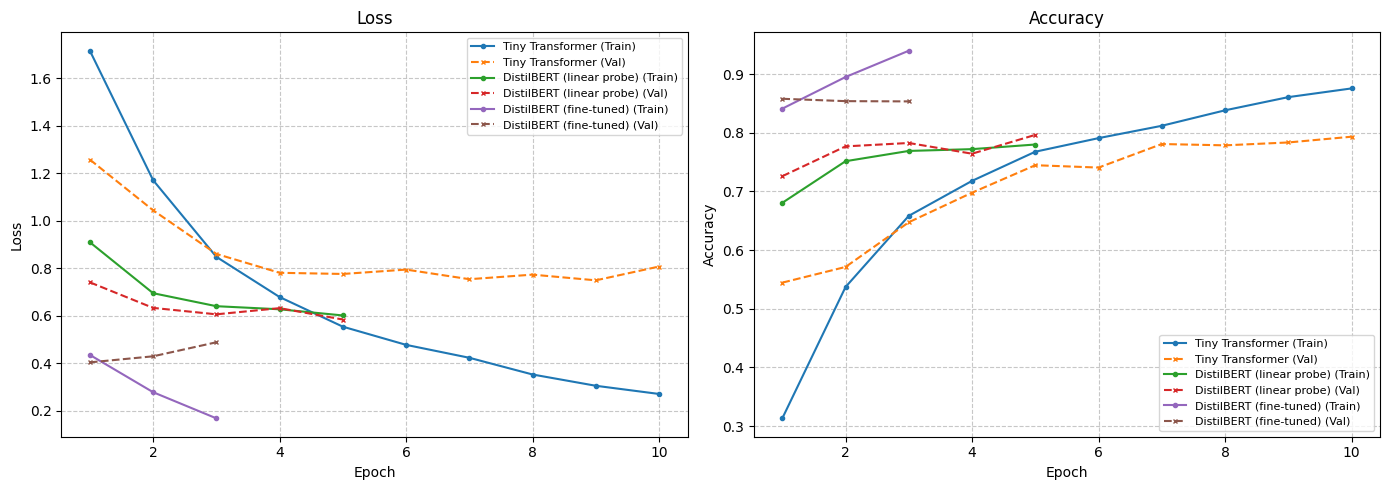

In [14]:
# Step 2: Fine-tuning — unfreeze the backbone and continue training the SAME model
# (Same sequential workflow as Week 5: linear probing first, then fine-tune)
for param in distilbert.distilbert.parameters():
    param.requires_grad = True

trainable = sum(p.numel() for p in distilbert.parameters() if p.requires_grad)
print(f'Step 2: Fine-Tuning')
print(f'  Trainable: {trainable:,} / {total:,} ({trainable/total*100:.2f}%)')

# New optimizer with ALL parameters and a MUCH smaller learning rate
optimizer = optim.AdamW(distilbert.parameters(), lr=2e-5, weight_decay=0.01)

all_results['DistilBERT (fine-tuned)'] = run_experiment(
    distilbert, optimizer, criterion, hf_train_loader, hf_val_loader,
    epochs=3, name='DistilBERT fine-tune', tokenizer_mode=True
)

plot_experiments(all_results)

### 🤔 Questions 

1. Why are transformer learning rates (2e-5) much smaller than what we used for RNNs (1e-3)?
2. How does fine-tuning a pretrained transformer compare to the linear probing → fine-tuning workflow from Week 5?
3. DistilBERT has 66M parameters while our LSTM had ~600k. Does this guarantee better performance? What are the trade-offs?
4. Why do we only train for 3 epochs instead of 10–20?

*Double-click here to write your answers...*

---
# Part 6: Compare All Models

Let's bring together all the models from Week 7 and Week 8.

In [15]:
# Summary table
# Add your Week 7 results manually if needed
print(f'{"Model":<30} {"Best Val Acc":<15} {"Epochs":<10}')
print('=' * 55)
for name, hist in all_results.items():
    best_val = max(hist['val_acc'])
    n_epochs = len(hist['val_acc'])
    print(f'{name:<30} {best_val:<15.4f} {n_epochs:<10}')

# Add Week 7 results for comparison (fill in from your Week 7 notebook)
print('\n--- From Week 7 (fill in manually) ---')
print(f'{"Bag of Embeddings":<30} {"~0.79":<15}')
print(f'{"LSTM":<30} {"~0.80":<15}')
print(f'{"LSTM + GloVe":<30} {"~0.83":<15}')

Model                          Best Val Acc    Epochs    
Tiny Transformer               0.7932          10        
DistilBERT (linear probe)      0.7963          5         
DistilBERT (fine-tuned)        0.8578          3         

--- From Week 7 (fill in manually) ---
Bag of Embeddings              ~0.79          
LSTM                           ~0.80          
LSTM + GloVe                   ~0.83          


### 🤔 Questions 

1. Which model achieved the best validation accuracy?
2. Which model was most parameter-efficient (best accuracy per parameter)?
3. Which model trained fastest (wall-clock time, not just epochs)?
4. Are transformers always the best choice? When might simpler models be preferable?

*Double-click here to write your answers...*

---
# Part 7: Analyse Transformer Predictions 

In [16]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

distilbert.eval()
all_preds, all_labels_list = [], []

with torch.inference_mode():
    for batch in hf_val_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        y = batch['labels']
        outputs = distilbert(input_ids=input_ids, attention_mask=attention_mask)
        _, predicted = torch.max(outputs.logits, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels_list.extend(y.numpy())

all_preds = np.array(all_preds)
all_labels_arr = np.array(all_labels_list)

print(classification_report(all_labels_arr, all_preds, target_names=label_names))

                  precision    recall  f1-score   support

     achievement       0.87      0.87      0.87       759
       affection       0.94      0.91      0.92       763
         bonding       0.88      0.95      0.91       239
enjoy_the_moment       0.63      0.65      0.64       249
        exercise       0.74      0.85      0.79        27
         leisure       0.76      0.70      0.73       166
          nature       0.72      0.80      0.76        41

        accuracy                           0.85      2244
       macro avg       0.79      0.82      0.80      2244
    weighted avg       0.85      0.85      0.85      2244



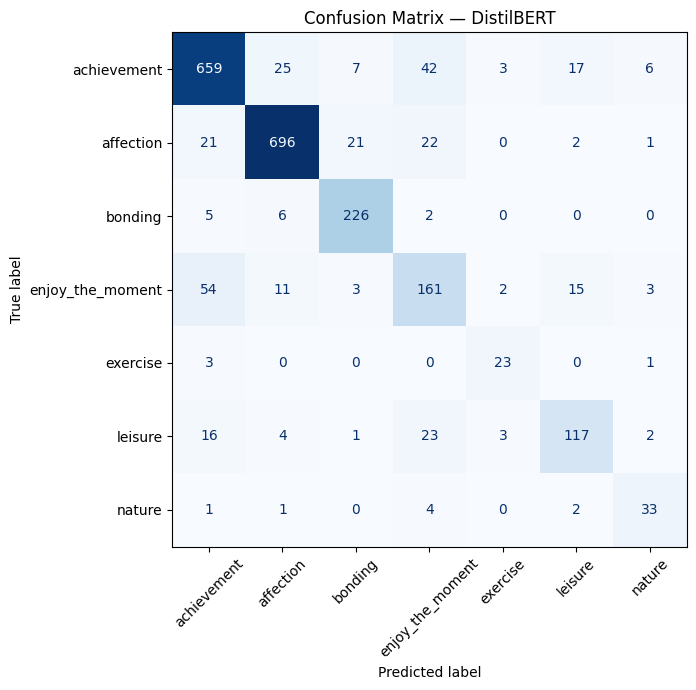

In [17]:
cm = confusion_matrix(all_labels_arr, all_preds)
fig, ax = plt.subplots(figsize=(8, 7))
disp = ConfusionMatrixDisplay(cm, display_labels=label_names)
disp.plot(ax=ax, xticks_rotation=45, cmap='Blues', colorbar=False)
plt.title('Confusion Matrix — DistilBERT')
plt.tight_layout()
plt.show()

### Test on Crafted Examples

In [18]:
# Test the transformer on specific examples
test_sentences = [
    "I had dinner with my family",
    "I went to the gym and ran five miles",
    "I got a promotion at work today",
    "I enjoyed a beautiful sunset at the beach",
    "I thought the trip would be fun but it was exhausting",
    "I am not unhappy about the result",
]

distilbert.eval()
for sent in test_sentences:
    encoded = tokenizer(sent, return_tensors='pt', truncation=True, max_length=64).to(device)
    with torch.inference_mode():
        logits = distilbert(**encoded).logits
        probs = torch.softmax(logits, dim=1)
        pred_idx = logits.argmax(dim=1).item()
    
    print(f'  "{sent}"')
    print(f'  → {label_names[pred_idx]} ({probs[0][pred_idx].item():.2%} confidence)\n')

  "I had dinner with my family"
  → affection (100.00% confidence)

  "I went to the gym and ran five miles"
  → exercise (100.00% confidence)

  "I got a promotion at work today"
  → achievement (99.98% confidence)

  "I enjoyed a beautiful sunset at the beach"
  → enjoy_the_moment (64.79% confidence)

  "I thought the trip would be fun but it was exhausting"
  → enjoy_the_moment (75.57% confidence)

  "I am not unhappy about the result"
  → achievement (81.28% confidence)



### Inspect Misclassified Examples

In [19]:
errors = np.where(all_preds != all_labels_arr)[0]
print(f'Misclassified: {len(errors)} / {len(all_labels_arr)} ({len(errors)/len(all_labels_arr)*100:.1f}%)\n')

print('Sample misclassified examples:')
print('-' * 80)
for i in range(min(10, len(errors))):
    idx = errors[i]
    text = X_val[idx]
    true_label = label_names[all_labels_arr[idx]]
    pred_label = label_names[all_preds[idx]]
    print(f'  True: {true_label:<20} Pred: {pred_label:<20}')
    print(f'  "{text[:120]}"')
    print()

Misclassified: 329 / 2244 (14.7%)

Sample misclassified examples:
--------------------------------------------------------------------------------
  True: leisure              Pred: affection           
  "I went shopping and got some new dresses. Shopping is a stress buster and a happy exercise for me."

  True: achievement          Pred: enjoy_the_moment    
  "I realized I hadn't had a drink in over a month and that I didn't miss drinking at all."

  True: affection            Pred: bonding             
  "My dog gave my roommate's rabbit very cute little kisses on the head."

  True: enjoy_the_moment     Pred: achievement         
  "Today was opening day for Major League Baseball and I wore my team's shirt to work."

  True: leisure              Pred: enjoy_the_moment    
  "yesterday we went to queen bar. we really enjoyed after a long time."

  True: achievement          Pred: affection           
  "it was a small gesture but this parent saw many of my daily challenges.she has 

### 🤔 Questions

1. Does the transformer handle the negation example (*"I am not unhappy"*) better than the LSTM would?
2. Are the confusion patterns similar to or different from the LSTM's confusion matrix in Week 7?
3. What types of examples are still difficult for the transformer? Why?
4. Does the transformer make any confident but wrong predictions? What does this tell you?

*Double-click here to write your answers...*

---
# Part 8: Bias, Ethics & Practical Considerations 

Pretrained transformers like DistilBERT were trained on large web text corpora (Wikipedia, BookCorpus). This raises important concerns:

### Bias in Pretrained Models

The training data reflects the biases of its authors and sources. These biases are encoded into the model's representations and can affect downstream tasks. For example, word associations may reflect gender stereotypes, cultural biases, or demographic skews in the training data.

### Computational and Environmental Cost

| Model | Parameters | Training Cost (estimated) |
|---|---|---|
| Our LSTM | ~600K | Minutes on a laptop |
| DistilBERT | 66M | ~90 hours on 8 GPUs |
| BERT-Large | 340M | ~4 days on 64 TPUs |
| GPT-3 | 175B | ~$4.6M in compute |

Fine-tuning is cheap, but pretraining is extremely expensive in both compute and carbon emissions.

### 🤔 Questions 

1. Why might a model pretrained on Wikipedia and books perform differently on social media text or medical notes?
2. If DistilBERT has inherited biases, how might this affect our happiness category predictions?
3. Given the computational cost of transformers, when is it justified to use them vs simpler models?
4. What responsibility do practitioners have when deploying models that contain biases?

*Double-click here to write your answers...*

---
# Part 9: Mini Challenge 

Improve the transformer-based classifier. Try one or more:

- **Learning rate tuning:** Try 1e-5, 2e-5, 5e-5
- **Freeze then fine-tune:** Freeze the transformer body, train only the head, then unfreeze and fine-tune (Week 5 workflow)
- **Different pretrained model:** Try `bert-base-uncased` or `roberta-base`
- **Longer training:** 5 epochs instead of 3 (watch for overfitting)
- **Learning rate scheduler:** Linear warmup + decay

In [20]:
# Your code here
# ...

# Example: Linear probing then fine-tuning
# Step 1: Freeze backbone
# for param in model.distilbert.parameters():
#     param.requires_grad = False
# optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)
# ... train for 2 epochs ...

# Step 2: Unfreeze and fine-tune
# for param in model.parameters():
#     param.requires_grad = True
# optimizer = optim.AdamW(model.parameters(), lr=2e-5)
# ... train for 3 more epochs ...

### Final Test Evaluation

In [21]:
# 🚨 Do this ONCE with your best model
# best_model = distilbert  # or your improved model
# test_loss, test_acc = evaluate_model(best_model, hf_test_loader, criterion, tokenizer_mode=True)
# print(f'Final Test Accuracy: {test_acc:.4f}')

---
# Part 10: Reflection

1. Why did transformers largely replace recurrent models in NLP?
2. What is the key idea behind self-attention? How does it differ from the RNN hidden state?
3. What trade-offs exist when choosing between a transformer and an LSTM for a given task?
4. When might simpler models (LSTM, GRU, or even bag-of-words) still be preferable to transformers?
5. How does the transition from RNNs to transformers parallel the transition from simple CNNs to pretrained models (ResNet) that we saw in Weeks 4–5?

*Double-click here to write your reflection...*


## 🔑 Key Takeaway

Transformers use self-attention to model contextual relationships between all tokens simultaneously, overcoming the sequential bottleneck and vanishing gradient limitations of RNNs. Pretrained transformers (BERT, DistilBERT, etc.) are the NLP equivalent of pretrained CNNs — they encode vast linguistic knowledge that transfers to downstream tasks with minimal fine-tuning. Understanding **when** to use transformers vs simpler models, and **how** to fine-tune responsibly, is a core skill in modern deep learning.

